# Controlled learned GCN representation integration
Separate validation-only experiment. Compare a temporal anchor, an optional degree-MLP branch and an optional GCN branch. The graph arms have paired weights and equal parameter counts. All canonical users remain eligible for classification. See `reports/GCN_INTEGRATION_EXPERIMENT.md` for the prespecified protocol.
No test scoring, threshold tuning, learned gates, text changes or contrastive learning. Split graphs are gold-isolated, with possible shared support nodes. Missing graph representations are explicitly masked; missing temporal observations retain their masks.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/gcn_integration_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.gcn_integration import run, verify
print('Repository:', ROOT)

C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\env\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Repository: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation


## End-to-end paired training
All 671 training users; seeds 42/43/44, 50 epochs, fixed class weight 540/131 and threshold 0.5. Best checkpoint uses minimum unweighted validation BCE on all 144 users. The GCN is recomputed with gradients on the training graph for each minibatch. Validation uses its own graph in eval mode. Each execution creates a new immutable output directory.

In [2]:
output_dir, metrics_table, seed_summary = run(ROOT)
print('OUTPUT_VERSION:', output_dir)
display(seed_summary[seed_summary.policy.eq('best_unweighted_validation_loss')])

Training temporal_anchor, seed 42


temporal_anchor seed 42, epoch 10: validation BCE 0.6026


temporal_anchor seed 42, epoch 20: validation BCE 0.5949


temporal_anchor seed 42, epoch 30: validation BCE 0.6159


temporal_anchor seed 42, epoch 40: validation BCE 0.6551


...

gcn seed 44, epoch 30: validation BCE 0.5817


gcn seed 44, epoch 40: validation BCE 0.5799


gcn seed 44, epoch 50: validation BCE 0.6062


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\gcn_integration_v1\20260921T103149397425Z_0df4d0e8


,arm,policy,cohort,bot_f1_mean,bot_f1_std,bot_precision_mean,bot_precision_std,bot_recall_mean,bot_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,degree_mlp,best_unweighted_validation_loss,all,0.387752,0.058232,0.301241,0.052361,0.547619,0.074345,0.688424,0.052207,0.372620,0.110236
1,degree_mlp,best_unweighted_validation_loss,graph_available,0.273810,0.286457,0.523810,0.501698,0.238095,0.297381,0.903401,0.049206,0.757078,0.056333
2,degree_mlp,best_unweighted_validation_loss,graph_unavailable,0.394263,0.027723,0.284818,0.035330,0.650794,0.054986,0.677445,0.050900,0.394443,0.122270
6,gcn,best_unweighted_validation_loss,all,0.428347,0.091277,0.331853,0.078713,0.607143,0.107143,0.715517,0.076709,0.435573,0.137921
7,gcn,best_unweighted_validation_loss,graph_available,0.386111,0.337509,0.351852,0.305976,0.428571,0.377964,0.889796,0.057579,0.748473,0.099976
8,gcn,best_unweighted_validation_loss,graph_unavailable,0.421286,0.059576,0.310774,0.060192,0.666667,0.047619,0.697433,0.063015,0.444712,0.133437
12,temporal_anchor,best_unweighted_validation_loss,all,0.478561,0.013175,0.377577,0.019443,0.654762,0.020620,0.767857,0.008052,0.552904,0.016508
13,temporal_anchor,best_unweighted_validation_loss,graph_available,0.600490,0.021226,0.518519,0.032075,0.714286,0.000000,0.854422,0.014334,0.707825,0.024450
14,temporal_anchor,best_unweighted_validation_loss,graph_unavailable,0.444639,0.011405,0.342593,0.016038,0.634921,0.027493,0.735450,0.005125,0.523638,0.021493


In [3]:
verification = verify(ROOT, output_dir)
assert verification['training_runs'] == 9
assert verification['checkpoints_reloaded'] == 18
assert verification['test_inputs_parsed'] == 0
print(verification)

{'training_runs': 9, 'checkpoints_reloaded': 18, 'validation_prediction_files': 18, 'test_inputs_parsed': 0, 'identity_only_assignment_projection': True, 'temporal_anchor_reproduced': True, 'protected_files_at_execution': 726}


,split,canonical_users,graph_available,graph_unavailable,graph_nodes,observed_directed_edges,eligible_bots,forbidden_gold_endpoints
0,train,671,193,478,42954,60924,31,0
1,validation,144,42,102,11436,13006,7,0


,seed,policy,cohort,comparison,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision
0,42,best_unweighted_validation_loss,all,gcn_minus_degree_mlp,-0.042235,-0.029807,-0.071429,-0.065887,-0.055587
1,42,best_unweighted_validation_loss,all,gcn_minus_temporal_anchor,-0.141951,-0.125968,-0.142857,-0.145936,-0.258146
2,42,best_unweighted_validation_loss,graph_available,gcn_minus_degree_mlp,-0.250000,-1.000000,-0.142857,0.053061,0.102833
3,42,best_unweighted_validation_loss,graph_available,gcn_minus_temporal_anchor,-0.588235,-0.500000,-0.714286,0.097959,0.135590
4,42,best_unweighted_validation_loss,graph_unavailable,gcn_minus_degree_mlp,-0.025316,-0.017241,-0.047619,-0.034685,-0.051892
5,42,best_unweighted_validation_loss,graph_unavailable,gcn_minus_temporal_anchor,-0.078903,-0.091954,0.047619,-0.116402,-0.217631
12,43,best_unweighted_validation_loss,all,gcn_minus_degree_mlp,0.157895,0.113782,0.250000,0.133929,0.219512
13,43,best_unweighted_validation_loss,all,gcn_minus_temporal_anchor,0.025000,0.019231,0.035714,0.009236,-0.049305
14,43,best_unweighted_validation_loss,graph_available,gcn_minus_degree_mlp,0.625000,0.555556,0.714286,-0.073469,-0.105771
15,43,best_unweighted_validation_loss,graph_available,gcn_minus_temporal_anchor,0.036765,0.055556,0.000000,0.040816,0.025920


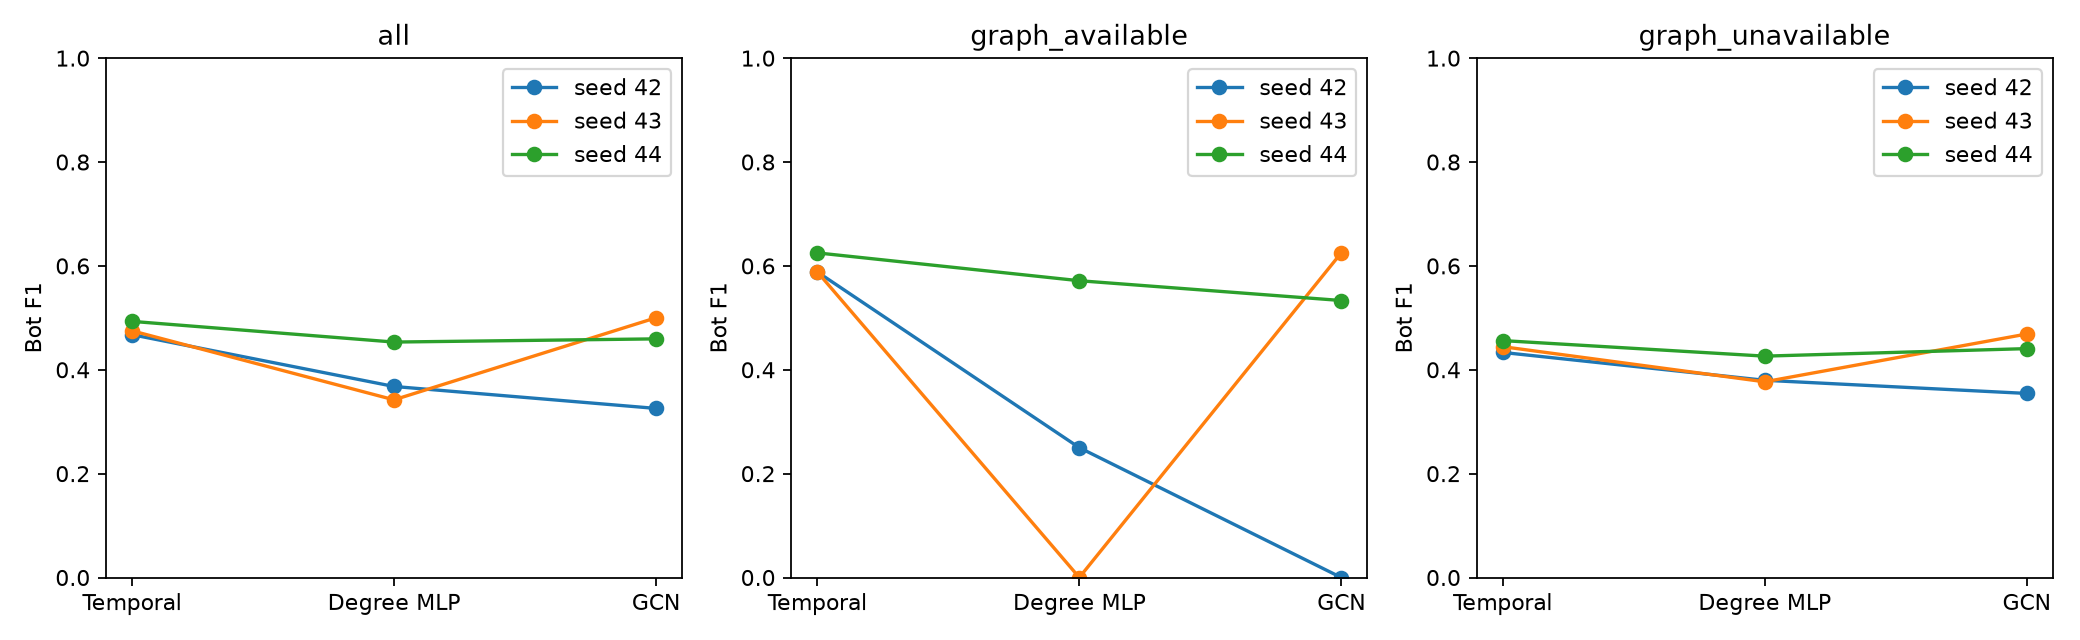

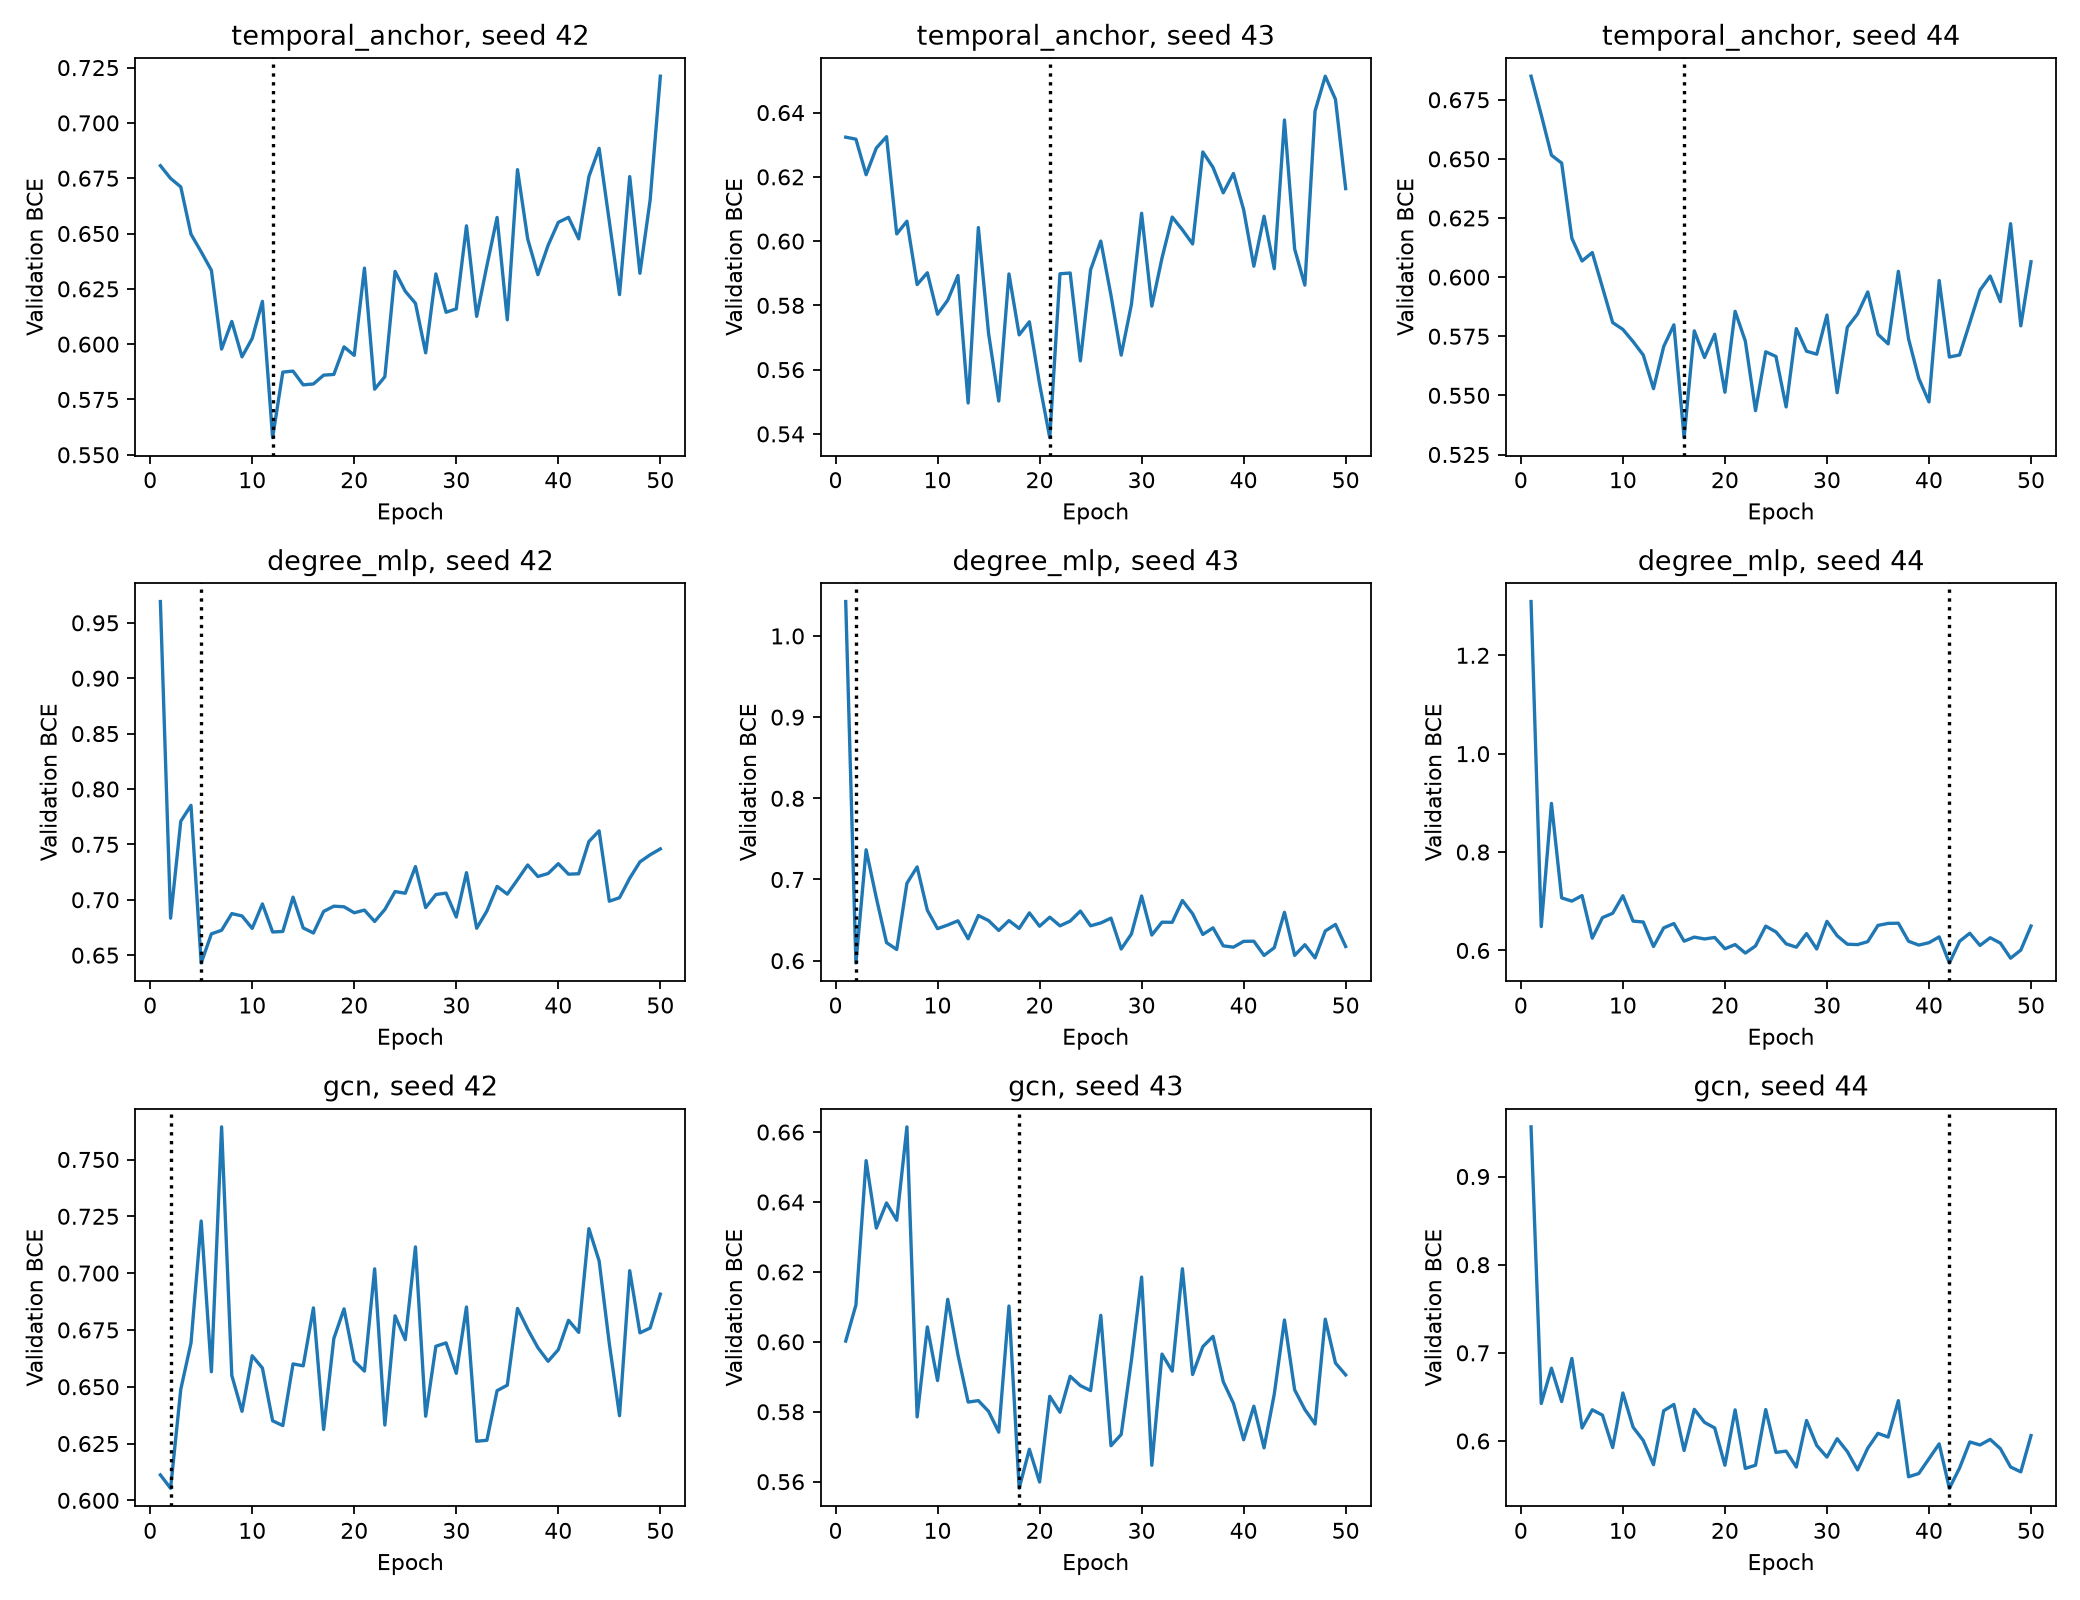

In [4]:
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv(output_dir / 'graph_coverage.csv'))
effects = pd.read_csv(output_dir / 'paired_effects.csv')
display(effects[effects.policy.eq('best_unweighted_validation_loss')])
display(Image(filename=str(output_dir / 'figures/paired_cohort_f1.png')))
display(Image(filename=str(output_dir / 'figures/validation_curves.png')))

## Interpretation limits
GCN minus degree MLP isolates message passing at matched capacity and initialization. GCN minus temporal anchor also changes capacity and available information. Graph-available validation contains only seven bots among 42 users; report all seeds and avoid significance claims. Selection and reporting reuse validation data. No model is automatically promoted, and the final test protocol is unchanged. The anchor must reproduce the frozen temporal experiment during verification.